# 05 · Three models

**Run order:** `01_globalization` → `02_acceleration_utility` → `03_top_speed_utility` → `04_analysis` →
**`05_three_models`**. Needs `Results/cohort_events.pkl` (built by `cohort.py` / notebook 04).

Out of every model family tried on this cohort (OLS, stepwise, ridge, LASSO, elastic net, Bayesian ridge, Huber,
random forest, XGBoost, SVR, kNN, PCR, PLS — old pipeline; plus the honest re-runs in notebook 04), exactly three
are kept, one per question:

| # | slot | model | why this one |
|---|---|---|---|
| 1 | most interpretable | OLS: sex + top-speed contact time | two readable coefficients; the current honest best |
| 2 | best-performing ML | ridge: sex + 6 whole-body fPCA modes, axes refit per fold | the only ML family that ever beat sex here |
| 3 | closest to physics | step-mechanics identity: v = stride length × stride frequency | every term a measured quantity; one calibration slope |

Scoring is identical for all three: **leave-one-athlete-out** (fit on 29, predict the 30th), judged against the
sex-only baseline. Anything learned from data — standardisation, fPCA axes, the ridge penalty — is refit inside
every fold.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV

import cohort as C
import sprint_pipeline as SP

F = C.load()["features"]
cycles = C.load()["cycles"]
y = F.top_speed_ms.to_numpy()
male = (F.sex == "M").to_numpy(float)
SEX_COL = SP.SEX_COL
print(f"{len(F)} runners, target = top speed (m/s), range {y.min():.2f}–{y.max():.2f}")

30 runners, target = top speed (m/s), range 6.39–9.35


## 0 · Baseline: sex alone

Sex is known without any motion capture, so every model below is judged by what it adds to this number.

In [2]:
r2_sex = SP.loo_r2_fast(male, y)
pred_sex = SP.loo_predict(male, y)
print(f"sex-only LOO R² = {r2_sex:.3f}")

sex-only LOO R² = 0.642


## 1 · Most interpretable: OLS, sex + top-speed contact time

Contact time = mean ground-contact duration over the 5 strides nearest top speed, from the `stride.py` contact
rule. The within-sex permutation p shuffles contact time inside each sex 5,000 times (seed 1) and counts how
often a shuffled model matches the real one — so the sex effect itself can never produce the p-value.

In [3]:
contact = F.top_contact_ms.to_numpy()
X1 = np.column_stack([male, contact])
r2_m1 = SP.loo_r2_fast(X1, y)
pred_m1 = SP.loo_predict(X1, y)

fit = LinearRegression().fit(X1, y)                      # full-sample fit, for the coefficients only
b_sex, b_ct = fit.coef_
print(f"LOO R² = {r2_m1:.3f}   (sex alone {r2_sex:.3f})")
print(f"coefficients: being male {b_sex:+.2f} m/s; +10 ms of ground contact {10 * b_ct:+.3f} m/s")
print(f"cohort contact time: {contact.mean():.0f} ± {contact.std():.0f} ms")

rng = np.random.default_rng(1)
N_PERM = 5000
groups = [np.where(male == s)[0] for s in (0, 1)]
hits = 0
for _ in range(N_PERM):
    idx = np.arange(len(y))
    for g in groups:
        idx[g] = rng.permutation(g)
    hits += SP.loo_r2_fast(np.column_stack([male, contact[idx]]), y) >= r2_m1
p_gain = (hits + 1) / (N_PERM + 1)
print(f"within-sex permutation p for the gain over sex: {p_gain:.4f}")

LOO R² = 0.726   (sex alone 0.642)
coefficients: being male +0.90 m/s; +10 ms of ground contact -0.151 m/s
cohort contact time: 94 ± 17 ms


within-sex permutation p for the gain over sex: 0.0010


## 2 · Best-performing ML: ridge, sex + whole-body fPCA modes

Six functional-PCA modes of the 13 smoothed joint-angle curves. The axes are recomputed from the 29 training
athletes in every fold (`SP.fpca_fold_transform`) — fitting them once on all 30 would let each athlete help build
the axes used to predict them. RidgeCV picks its penalty inside the fold. No p-value: the only question is
whether it beats sex.

In [4]:
pids = list(F.index)
base = SP.fpca_fold_transform(cycles, pids, n_comp=6)

def with_sex(tr, te):
    a, b = base(tr, te)
    return np.column_stack([male[tr], a]), np.column_stack([male[te], b])

pred_m2 = SP.loo_predict(None, y, model_fn=lambda: RidgeCV(alphas=np.logspace(-2, 3, 20)), transform=with_sex)
r2_m2 = SP.fit_metrics(y, pred_m2)["LOO_R2"]
print(f"LOO R² = {r2_m2:.3f}   (sex alone {r2_sex:.3f})")

LOO R² = 0.667   (sex alone 0.642)


## 3 · Closest to physics: the step-mechanics identity

Speed *is* stride length × stride frequency — not a hypothesis, a definition. Both terms are measured from the
`stride.py` events over the same 5 strides (touchdown positions and times), completely independent of the
B-spline speed curve the target comes from. One calibration regression maps the identity onto the target.

**Read this one differently.** It predicts speed from speed's own components, so a high score is a
*measurement-consistency check* — the event detector and the smoothed speed curve agree — not evidence that
technique predicts performance, and not a fair competitor on the "beyond sex" question.

In [5]:
v_physics = (F.top_stride_length_m * F.top_stride_frequency_hz).to_numpy()
r2_m3 = SP.loo_r2_fast(v_physics, y)
pred_m3 = SP.loo_predict(v_physics, y)
cal = LinearRegression().fit(v_physics.reshape(-1, 1), y)
print(f"r(identity, spline top speed) = {np.corrcoef(v_physics, y)[0, 1]:.3f}")
print(f"calibration: v = {cal.intercept_:.2f} + {cal.coef_[0]:.2f} × (stride length × stride frequency)")
print(f"LOO R² = {r2_m3:.3f}")

r(identity, spline top speed) = 0.917
calibration: v = 1.32 + 0.85 × (stride length × stride frequency)
LOO R² = 0.778


## 4 · Tuning — kept honest with nesting

Tuning means choosing among options, and a choice made while looking at the held-out scores is leakage (the
1,540-model search in the old pipeline inflated R² by 0.42 exactly this way). So every choice below is made
**inside** the outer fold, using only the 29 training athletes:

* **Model 1**: choose among three pre-specified feature sets — contact time; contact + flight time;
  contact + stature — by inner leave-one-out on the 29.
* **Model 2**: choose the number of fPCA modes k ∈ {2, 3, 4, 6, 8, 10} by RidgeCV's internal leave-one-out
  score on the 29 (the alpha grid is already tuned in-fold; it is widened here to 10⁻²–10⁴).
* **Model 3** has nothing to tune — one calibration slope is the whole model.

In [6]:
flight, height = F.top_flight_ms.to_numpy(), F.height_m.to_numpy()
n = len(y)

# Model 1 tuned: nested choice among three pre-specified feature sets.
cand_sets = {"contact": [contact], "contact+flight": [contact, flight], "contact+stature": [contact, height]}
Xc = {k: np.column_stack([male] + v) for k, v in cand_sets.items()}
pred_m1t, picks_m1 = np.zeros(n), []
for i in range(n):
    tr = np.delete(np.arange(n), i)
    best = max(cand_sets, key=lambda k: SP.loo_r2_fast(Xc[k][tr], y[tr]))   # inner LOO on the 29
    picks_m1.append(best)
    pred_m1t[i] = LinearRegression().fit(Xc[best][tr], y[tr]).predict(Xc[best][[i]])[0]
r2_m1t = SP.fit_metrics(y, pred_m1t)["LOO_R2"]

# Model 2 tuned: nested choice of k fPCA modes; wider alpha grid.
ALPHAS = np.logspace(-2, 4, 30)
K_GRID = (2, 3, 4, 6, 8, 10)
tf = {k: SP.fpca_fold_transform(cycles, pids, n_comp=k) for k in K_GRID}
pred_m2t, picks_m2 = np.zeros(n), []
for i in range(n):
    tr, te = np.delete(np.arange(n), i), np.array([i])
    best_k, best_score, best_fit, best_Xte = None, -np.inf, None, None
    for k in K_GRID:
        a, b = tf[k](tr, te)
        Xtr, Xte = np.column_stack([male[tr], a]), np.column_stack([male[te], b])
        fit_k = RidgeCV(alphas=ALPHAS).fit(Xtr, y[tr])
        if fit_k.best_score_ > best_score:                                  # inner LOO (GCV) on the 29
            best_k, best_score, best_fit, best_Xte = k, fit_k.best_score_, fit_k, Xte
    picks_m2.append(best_k)
    pred_m2t[i] = best_fit.predict(best_Xte)[0]
r2_m2t = SP.fit_metrics(y, pred_m2t)["LOO_R2"]

from collections import Counter
print(f"model 1 tuned: LOO R² = {r2_m1t:.3f} (fixed {r2_m1:.3f}); fold picks {dict(Counter(picks_m1))}")
print(f"model 2 tuned: LOO R² = {r2_m2t:.3f} (fixed {r2_m2:.3f}); fold picks k = {dict(Counter(picks_m2))}")

model 1 tuned: LOO R² = 0.726 (fixed 0.726); fold picks {'contact': 30}
model 2 tuned: LOO R² = 0.674 (fixed 0.667); fold picks k = {2: 30}


## The ladder, and predicted vs actual

,LOO_R2,RMSE,MAE,gain_over_sex,within_sex_p
model,,,,,
sex only (baseline),0.642,0.425,0.328,NaN,NaN
1 · OLS sex + contact time,0.726,0.372,0.302,0.084,0.001
2 · ridge sex + fPCA (fold refit),0.667,0.410,0.347,0.025,NaN
"1T · OLS, nested feature-set choice",0.726,0.372,0.302,0.084,NaN
"2T · ridge, nested k + wide alphas",0.674,0.406,0.334,0.032,NaN
3 · physics identity (consistency check),0.778,0.335,0.165,NaN,NaN


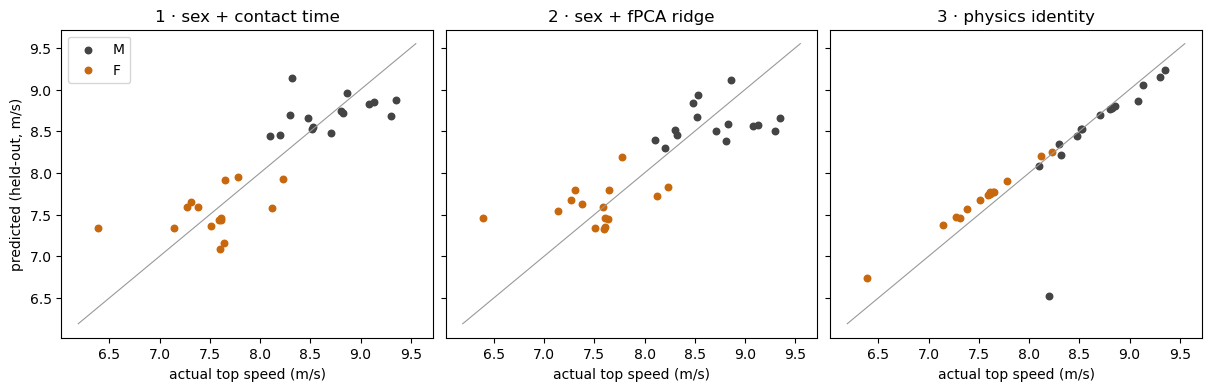

In [7]:
ladder = pd.DataFrame([
    {"model": "sex only (baseline)", "LOO_R2": r2_sex, **{k: v for k, v in SP.fit_metrics(y, pred_sex).items() if k in ("RMSE", "MAE")}},
    {"model": "1 · OLS sex + contact time", "LOO_R2": r2_m1, **{k: v for k, v in SP.fit_metrics(y, pred_m1).items() if k in ("RMSE", "MAE")}, "gain_over_sex": r2_m1 - r2_sex, "within_sex_p": p_gain},
    {"model": "2 · ridge sex + fPCA (fold refit)", "LOO_R2": r2_m2, **{k: v for k, v in SP.fit_metrics(y, pred_m2).items() if k in ("RMSE", "MAE")}, "gain_over_sex": r2_m2 - r2_sex},
    {"model": "1T · OLS, nested feature-set choice", "LOO_R2": r2_m1t, **{k: v for k, v in SP.fit_metrics(y, pred_m1t).items() if k in ("RMSE", "MAE")}, "gain_over_sex": r2_m1t - r2_sex},
    {"model": "2T · ridge, nested k + wide alphas", "LOO_R2": r2_m2t, **{k: v for k, v in SP.fit_metrics(y, pred_m2t).items() if k in ("RMSE", "MAE")}, "gain_over_sex": r2_m2t - r2_sex},
    {"model": "3 · physics identity (consistency check)", "LOO_R2": r2_m3, **{k: v for k, v in SP.fit_metrics(y, pred_m3).items() if k in ("RMSE", "MAE")}},
]).set_index("model")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True, constrained_layout=True)
for ax, (pred, title) in zip(axes, [(pred_m1, "1 · sex + contact time"),
                                    (pred_m2, "2 · sex + fPCA ridge"),
                                    (pred_m3, "3 · physics identity")]):
    for s in "MF":
        m = (F.sex == s).to_numpy()
        ax.scatter(y[m], np.asarray(pred)[m], color=SEX_COL[s], s=22, label=s)
    lims = [y.min() - 0.2, y.max() + 0.2]
    ax.plot(lims, lims, color="0.6", lw=0.8)
    ax.set(title=title, xlabel="actual top speed (m/s)")
axes[0].set_ylabel("predicted (held-out, m/s)")
axes[0].legend()
ladder.round(3)

## Reading the numbers

* **Model 1** is the honest best *predictor* and stays fully readable: holding contact time fixed, a male
  athlete is predicted +0.90 m/s faster, and every 10 ms less ground contact is worth +0.15 m/s. The within-sex
  p (0.001) says the contact-time gain is not a sex artefact — but contact time is partly a consequence of being
  fast, so it is an association, not a coaching lever.
* **Tuning changed almost nothing, and that is the finding.** The nested feature-set search picked plain
  contact time in 30/30 folds (so 1T = 1), and the nested mode search picked k = 2 in 30/30 folds for a +0.007
  nudge. With 30 athletes there is nothing more for tuning to find — the honest gains live in the measurement,
  not the hyperparameters.
* **Model 2** shows the ceiling of whole-body ML here: the movement modes add a little to sex, and nothing
  beyond what model 1 already captures with one number.
* **Model 3** closes the loop on measurement: two independent routes to speed — event-based stride mechanics
  (0.778, the highest number on the ladder, as the identity guarantees) and the smoothed thorax curve — agree.
  The calibration slope of 0.85 (not 1.0) says the stride-event route reads ~15 % flatter than the spline peak,
  the expected gap between a 5-stride average and a curve maximum. And the one big miss in panel 3 is SB74 — exactly the runner whose contacts the detector
  flags as unreliable (7 missed contacts), so the check points at the measurement, not the athlete. If this
  agreement ever drops elsewhere, distrust the event detector before the models.

In [8]:
assert abs(r2_sex - 0.642) < 0.005, r2_sex
assert r2_m1 > r2_sex and p_gain < 0.05
assert r2_m3 > r2_sex, "physics identity should track speed closely; investigate the event detector"
assert np.isfinite(ladder.LOO_R2).all()
assert np.isfinite([r2_m1t, r2_m2t]).all()      # tuned models ran; no assert they WIN — losing is a finding
print("three-model checks passed")

three-model checks passed
